# Análisis exploratorio (EDA)

Analizamos solo el conjunto de entrenamiento (`train.csv`).

In [1]:
import sys
sys.path.append("..")  

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import graficos as g

pd.set_option("display.max_columns", 30)

train = pd.read_csv("../data/silver/train.csv", parse_dates=["date_added"])
print(train.shape)
train.head()

(66903, 12)


,location_id,property_type,price,location,city,latitude,longitude,baths,bedrooms,date_added,dist_centro_km,Total_Area
0,1625,House,258894.27,DHA Defence,Lahore,31.485699,74.473604,7.0,6.0,2018-08-05,17.37,708.20
1,4191,House,172596.18,State Life Housing Society,Lahore,31.447081,74.396753,7.0,7.0,2018-08-05,16.31,505.86
2,12270,House,22270.47,Hakim Town,Lahore,31.418273,74.293919,4.0,3.0,2018-08-07,18.52,50.59
3,377,House,36189.52,Samanabad,Lahore,31.541117,74.296290,2.0,3.0,2018-08-07,5.53,113.82
4,1357,House,26167.81,Sanda,Lahore,31.559229,74.288321,2.0,2.0,2018-08-07,4.64,50.59


## 1. Tipos de variables

In [6]:
tipos = pd.DataFrame({
    "tipo": train.dtypes.astype(str),
    "valores_distintos": train.nunique(),
})
tipos

,tipo,valores_distintos
location_id,object,3863
property_type,object,2
price,float64,1483
location,object,1397
city,object,5
latitude,float64,6211
longitude,float64,6620
baths,float64,11
bedrooms,float64,11
date_added,datetime64[ns],133


## Conclusiones:

- Variables numéricas: "price", "Total_Area", "baths", "bedrooms", "dist_centro_km", "latitude" y "longitude".
- Variables Categóricas: "property_type", "city", "location"  y "location_id".

- "location_id" se lee como número, pero es un código, asi que la pasamos a texto para que no se trate como numérica.

In [3]:
train["location_id"] = train["location_id"].astype(str)
train.describe().round(1).T

,count,mean,min,25%,50%,75%,max,std
price,66903.0,141644.0,1057.8,40086.8,76833.1,150325.7,8073047.2,229276.9
latitude,66903.0,29.6,24.7,24.9,31.4,33.5,33.8,3.7
longitude,66903.0,71.3,66.8,67.1,73.1,74.3,74.5,3.2
baths,51925.0,4.1,1.0,3.0,4.0,5.0,11.0,1.8
bedrooms,59979.0,3.9,1.0,3.0,4.0,5.0,11.0,1.7
date_added,66903,2019-05-15 22:28:41.788260608,2018-08-05 00:00:00,2019-05-03 00:00:00,2019-06-26 00:00:00,2019-07-09 00:00:00,2019-08-06 00:00:00,NaN
dist_centro_km,66903.0,13.8,0.0,8.5,12.8,17.1,87.9,7.4
Total_Area,66903.0,244.3,10.1,118.9,161.9,252.9,4856.2,250.8


## 2. Valores ausentes


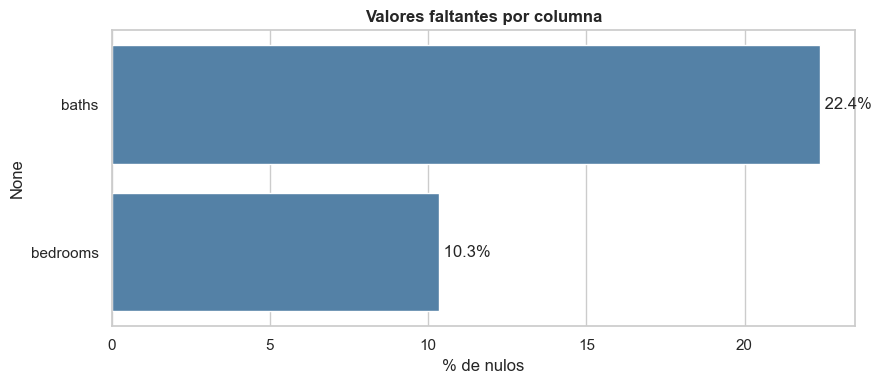

In [4]:
g.plot_valores_nulos(train);

In [5]:
print("% de ausentes por ciudad")
train.groupby("city")[["baths", "bedrooms"]].apply(lambda d: d.isna().mean()).round(3)

% de ausentes por ciudad


,baths,bedrooms
city,,
Faisalabad,0.453,0.366
Islamabad,0.200,0.114
Karachi,0.224,0.102
Lahore,0.203,0.061
Rawalpindi,0.245,0.138


## Conclusiones:

- Hay un 22 % de ausentes en "baths" y un 10 % en "bedrooms".

## Decisión: 

- Imputarlos ajustando solo con el train, con la mediana por tipo de vivienda y superficie y añadir una variable indicadora de dato ausente ("baths_ausente", "bedrooms_ausente"), porque el hecho de que falte puede aportar información.

---

## Lo que queda por hacer (guía)

Cada apartado con su gráfico y debajo **una celda Markdown con la conclusión y la acción**, como en los dos anteriores.

**3. Variable objetivo (`price`)**
- `g.plot_distribucion_numerica(train, "price");` y `g.plot_distribucion_numerica(train, "price", log=True);`
- Comparar la asimetría: `train["price"].skew()` y `np.log(train["price"]).skew()`.
- Acción esperada: modelar `log(price)`.

**4. Variables numéricas**
- `g.plot_distribuciones_numericas(train, cols=["Total_Area", "baths", "bedrooms", "dist_centro_km"]);`
- Atípicos: `g.plot_outliers_iqr(train, cols=["price", "Total_Area", "baths", "bedrooms", "dist_centro_km"]);`
- Discutir si los atípicos son errores o viviendas reales (casas grandes de 1 kanal o más). Acción: no quitarlos (ya se quitaron los errores en la limpieza) y usar escalado robusto o modelos de árboles.

**5. Variables categóricas**
- `g.plot_categorica(train, "city");`, `g.plot_categorica(train, "property_type");`, `g.plot_categorica(train, "location", top_n=20);`
- Cuántas zonas tienen pocos anuncios: `train["location"].value_counts().describe()`.
- Acción: *one-hot* para `city` y `property_type`; *target encoding* para `location` y `location_id`.

**6. Relación con el precio**
- `g.plot_correlaciones(train, cols=["price", "Total_Area", "baths", "bedrooms", "dist_centro_km"]);` (Spearman)
- `g.plot_scatter(train, "Total_Area", "price", hue="property_type");`
- `g.plot_boxplot_por_categoria(train, "city", "price");` y lo mismo con `"property_type"`.
- Idea de nueva variable: precio por m² medio de la zona (calculado solo con el train), baños por habitación, superficie por habitación.

**7. Ubicación**
- `g.plot_mapa_coordenadas(train);`
- Precio mediano según la distancia al centro.

**8. Fecha**
- `g.plot_serie_temporal(train, formato="%Y-%m-%d");` (en `train.csv` la fecha ya viene como `2019-07-17`).
- Acción esperada: no usarla como variable (es la fecha de la última actualización y la mayoría cae entre mayo y agosto de 2019).

**9. Tabla final de conclusiones y acciones**
Una tabla con todo lo anterior: qué hemos visto y qué haremos en la preparación (imputación, codificación, nuevas variables, escalado) y en el modelado.